**Ai-Based Smart Waste Segregation**

## 1. NumPy Fundamentals

In [27]:
import numpy as np

In [28]:
arr = np.arange(1,13)

In [29]:
arr

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12])

In [30]:
arr.shape

(12,)

In [31]:
arr.reshape(3,4)

array([[ 1,  2,  3,  4],
       [ 5,  6,  7,  8],
       [ 9, 10, 11, 12]])

## 2. Matplotlib Fundamentals

In [32]:
from matplotlib import pyplot as plt
from matplotlib import style
style.use('ggplot')

In [33]:
x1 = [1,2,3]

In [34]:
y1 = [1,2,3]

In [35]:
x2 = [33,11,23]

In [36]:
y2 = [1.111, 2,7]

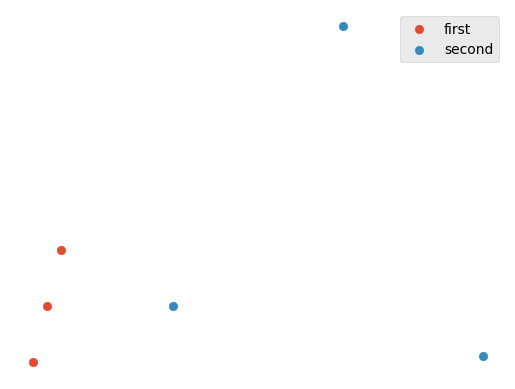

In [37]:
plt.scatter(x1,y1,label = "first")
plt.scatter(x2,y2,label="second")
plt.axis("off")
plt.legend()
plt.show()


## 3. Understanding Image Arrays

In [38]:
import numpy as np
from matplotlib import pyplot as plt

In [39]:
x = [[1,2,3],[4,5,6],[7,0,1]]
arr = np.array(x);

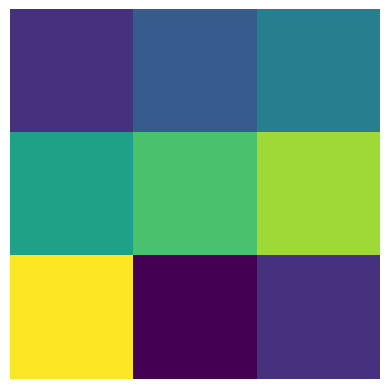

In [40]:
plt.axis("off")
plt.imshow(arr)
plt.show()

## 4. Image Loading and Preprocessing

In [41]:
import numpy as np
import matplotlib.pyplot as plt

In [42]:
image = np.zeros((100,100,3), dtype = np.uint8)
image[:, :, 0] = 255


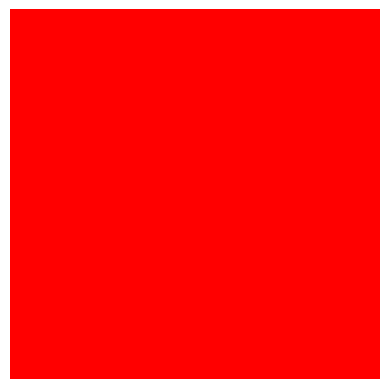

In [43]:
plt.axis("off")
plt.imshow(image)
plt.show()

In [44]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt


In [45]:
img = Image.open("/content/bottle.jpg")
img_arr = np.array(img)


FileNotFoundError: [Errno 2] No such file or directory: '/content/bottle.jpg'

In [ ]:
plt.imshow(img_arr)
plt.axis("off")
plt.show()


In [ ]:
img_arr.shape

In [ ]:
img_arr.dtype

In [ ]:
img_arr[0,0]

In [ ]:
img_arr[277,277]

In [ ]:
img_arr[553,553]

In [ ]:
img_arr.min(axis = (0,1))

In [ ]:
img_arr.max(axis = (0,1))

In [ ]:
print(img_arr[277, 277, 0])  # Red
print(img_arr[277, 277, 1])  # Green
print(img_arr[277, 277, 2])  # Blue

In [ ]:
img_resized = img.resize((224,224))

In [ ]:
img_resized.size


## 5. Dataset Extraction and Exploration

In [52]:
import zipfile

In [53]:
with zipfile.ZipFile("/content/dataset-resized.zip","r") as zip_ref:
  zip_ref.extractall("/content/dataset-resized")

In [54]:
with zipfile.ZipFile("/content/organic_only.zip","r") as zip_ref:
  zip_ref.extractall("/content/organic_only")

## 6. Dataset Preparation

In [55]:
import os

base_path = "/content/organic_only/organic_only"

for split in ["train", "val", "test"]:
    count = 0
    folder_path = os.path.join(base_path, split, "organic")
    images = os.listdir(folder_path)
    for filename in images:
      if filename.endswith(".jpeg") :
        count = count + 1
    print(split, ":", count, "files")

train : 574 files
val : 123 files
test : 122 files


In [59]:
import os
import random
import shutil

source_path = "/content/dataset-resized/dataset-resized"
output_path = "/content/waste_data"

random.seed(42)

categories = {
    "plastic": ["plastic"],
    "glass": ["glass"],
    "paper": ["paper", "cardboard"]
}

for final_category, source_categories in categories.items():
    for source_category in source_categories:
        folder_path = os.path.join(source_path, source_category)

        images = [
            filename for filename in os.listdir(folder_path)
            if filename.lower().endswith(".jpg")
        ]

        random.shuffle(images)

        total = len(images)
        train_end = int(total * 0.70)
        val_end = train_end + int(total * 0.15)

        splits = {
            "train": images[:train_end],
            "val": images[train_end:val_end],
            "test": images[val_end:]
        }

        for split, filenames in splits.items():
            destination = os.path.join(
                output_path, split, final_category
            )
            os.makedirs(destination, exist_ok=True)

            for filename in filenames:
                source_file = os.path.join(folder_path, filename)
                destination_file = os.path.join(destination, filename)
                shutil.copy2(source_file, destination_file)

        print(
            source_category,
            "->", final_category,
            "| train:", len(splits["train"]),
            "| val:", len(splits["val"]),
            "| test:", len(splits["test"])
        )

print("TrashNet splitting and copying complete!")

plastic -> plastic | train: 337 | val: 72 | test: 73
glass -> glass | train: 350 | val: 75 | test: 76
paper -> paper | train: 415 | val: 89 | test: 90
cardboard -> paper | train: 282 | val: 60 | test: 61
TrashNet splitting and copying complete!


In [51]:
import os
import shutil

organic_path = "/content/organic_only/organic_only"
output_path = "/content/waste_data"

for split in ["train", "val", "test"]:

    source_folder = os.path.join(
        organic_path, split, "organic"
    )

    destination_folder = os.path.join(
        output_path, split, "organic"
    )

    for filename in os.listdir(source_folder):

        if filename.lower().endswith((".jpg", ".jpeg", ".png")):

            source_file = os.path.join(source_folder, filename)
            destination_file = os.path.join(destination_folder, filename)

            shutil.copy2(source_file, destination_file)

print("Organic images copied successfully!")

Organic images copied successfully!


In [50]:
import os

base_path = "/content/waste_data"

for split in ["train", "val", "test"]:
    print("\n", split.upper())

    for category in ["plastic", "paper", "glass", "organic"]:
        folder_path = os.path.join(base_path, split, category)

        images = [
            f for f in os.listdir(folder_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(category, ":", len(images))



 TRAIN
plastic : 337
paper : 697
glass : 350
organic : 574

 VAL
plastic : 72
paper : 149
glass : 75
organic : 123

 TEST
plastic : 73
paper : 151
glass : 76
organic : 122


In [56]:
import os

base_path = "/content/dataset-resized/dataset-resized"

for split in ["cardboard", "glass", "metal", "paper", "plastic"]:
    count = 0
    folder_path = os.path.join(base_path, split)
    images = os.listdir(folder_path)
    for filename in images:
      if filename.endswith(".jpg") :
        count = count + 1
    print(split, count, "files")

cardboard 403 files
glass 501 files
metal 410 files
paper 594 files
plastic 482 files


In [57]:
import os

base_path = "/content/dataset-resized/dataset-resized"

for split in ["cardboard", "glass", "paper", "plastic"]:
    folder_path = os.path.join(base_path, split)
    print(split, ":", os.listdir(folder_path)[:5])

cardboard : ['cardboard355.jpg', 'cardboard164.jpg', 'cardboard38.jpg', 'cardboard85.jpg', 'cardboard398.jpg']
glass : ['glass242.jpg', 'glass199.jpg', 'glass448.jpg', 'glass493.jpg', 'glass65.jpg']
paper : ['paper546.jpg', 'paper466.jpg', 'paper109.jpg', 'paper308.jpg', 'paper38.jpg']
plastic : ['plastic10.jpg', 'plastic205.jpg', 'plastic293.jpg', 'plastic361.jpg', 'plastic106.jpg']


In [58]:
import os

output_path = "/content/waste_data"

for split in ["train", "val", "test"]:
    for category in ["plastic", "paper", "glass", "organic"]:
        folder_path = os.path.join(output_path, split, category)
        os.makedirs(folder_path, exist_ok=True)

print("Dataset folders created!")

Dataset folders created!


## 7. Loading the Dataset Using TensorFlow

In [46]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [47]:
import tensorflow as tf

base_path = "/content/waste_data"

class_names = ["glass", "organic", "paper", "plastic"]

train_ds = tf.keras.utils.image_dataset_from_directory(
    base_path + "/train",
    image_size=(224, 224),
    batch_size=32,
    class_names=class_names,
    label_mode="int",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    base_path + "/val",
    image_size=(224, 224),
    batch_size=32,
    class_names=class_names,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    base_path + "/test",
    image_size=(224, 224),
    batch_size=32,
    class_names=class_names,
    label_mode="int",
    shuffle=False
)

Found 1958 files belonging to 4 classes.
Found 419 files belonging to 4 classes.
Found 422 files belonging to 4 classes.


In [48]:
print("Class names:", train_ds.class_names)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

Class names: ['glass', 'organic', 'paper', 'plastic']
Training batches: 62
Validation batches: 14
Testing batches: 14


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Pixel value range: 0.0 to 255.0


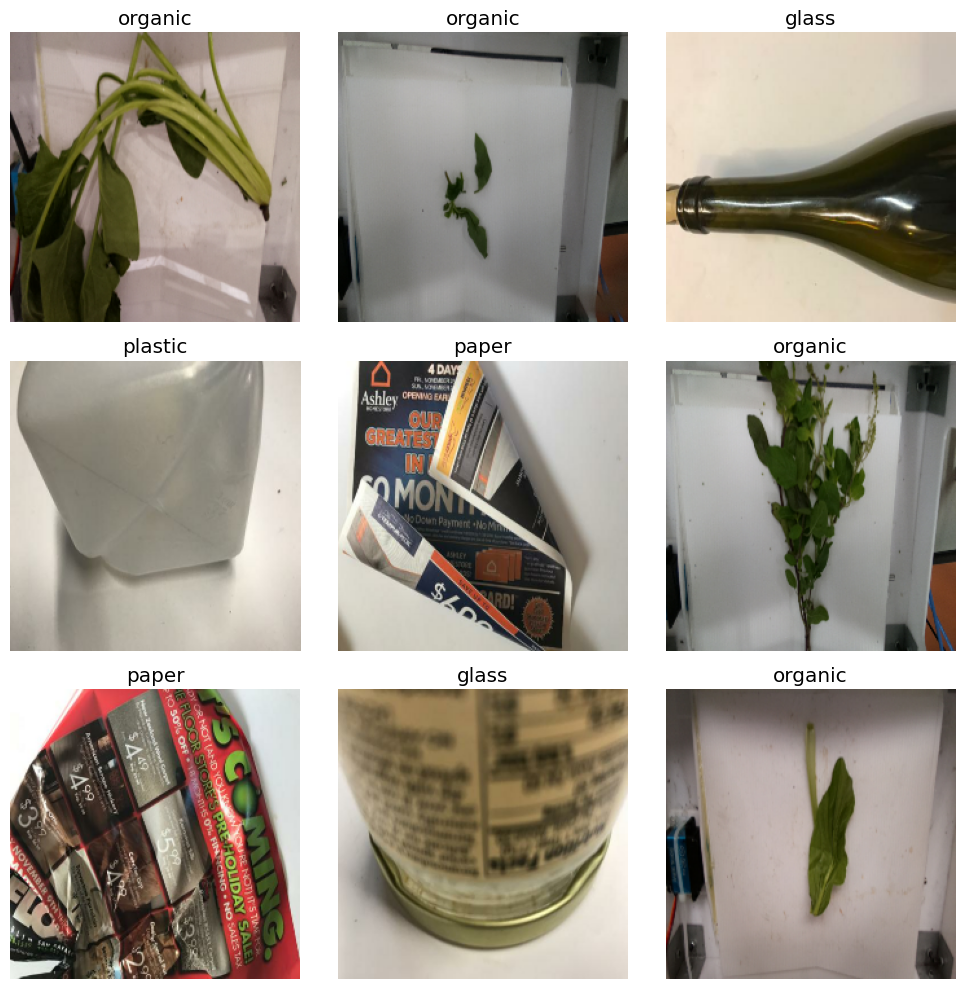

In [49]:
import matplotlib.pyplot as plt
import numpy as np

# Get one batch from the training dataset
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Pixel value range:", images.numpy().min(),
      "to", images.numpy().max())

# Display the first 9 images
plt.figure(figsize=(10, 10))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i].numpy()])
    plt.axis("off")

plt.tight_layout()
plt.show()